In [2]:
!pip install pandas
!pip install mongo
!pip install matplotlib
!pip install seaborn

In [3]:
#importo le libreirie necessarie per analizzare i dati
from pymongo import MongoClient
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import re

In [4]:
#importo i dati dal database e creo il mio data_set locale
client = MongoClient('mongodb://localhost:27017')

db = client['Football_Data']

collection_player_valutation = db['player_valutation']

documents = collection_player_valutation.find()

player_val_df = pd.DataFrame(list(documents)).drop('_id', axis=1)
player_val_df

,player_id,last_season,datetime,date,dateweek,market_value_in_eur,n,current_club_id,player_club_domestic_competition_id
0,3132,2013,2003-12-09 00:00:00,2003-12-09,2003-12-08,400000,1,126,TR1
1,6893,2012,2003-12-15 00:00:00,2003-12-15,2003-12-15,900000,1,984,GB1
2,10,2015,2004-10-04 00:00:00,2004-10-04,2004-10-04,7000000,1,398,IT1
3,26,2017,2004-10-04 00:00:00,2004-10-04,2004-10-04,1500000,1,16,L1
4,65,2015,2004-10-04 00:00:00,2004-10-04,2004-10-04,8000000,1,1091,GR1
...,...,...,...,...,...,...,...,...,...
440658,950091,2023,2023-09-21 00:00:00,2023-09-21,2023-09-18,1000000,1,1091,GR1
440659,968903,2023,2023-09-21 00:00:00,2023-09-21,2023-09-18,50000,1,653,GR1
440660,1031590,2023,2023-09-21 00:00:00,2023-09-21,2023-09-18,50000,1,6418,GR1
440661,1166093,2023,2023-09-21 00:00:00,2023-09-21,2023-09-18,50000,1,30120,GR1


In [7]:
player_val_df.columns

Index(['player_id', 'last_season', 'datetime', 'date', 'dateweek',
       'market_value_in_eur', 'n', 'current_club_id',
       'player_club_domestic_competition_id'],
      dtype='object')

In [8]:
#mantengo i dati che possono sembrare più utili: 'player_id', 'last_season','date' (valore molto simili ad altri due dati, quindi ne manterrò
#solo uno),'market_value_in_eur', 'current_club_id' e 'player_club_domestic_competition_id'. Inoltre analizzo 'n' non avendone capito il significato
val_df=player_val_df[['player_id', 'last_season','date','market_value_in_eur', 'n', 'current_club_id',
       'player_club_domestic_competition_id']]
val_df

,player_id,last_season,date,market_value_in_eur,n,current_club_id,player_club_domestic_competition_id
0,3132,2013,2003-12-09,400000,1,126,TR1
1,6893,2012,2003-12-15,900000,1,984,GB1
2,10,2015,2004-10-04,7000000,1,398,IT1
3,26,2017,2004-10-04,1500000,1,16,L1
4,65,2015,2004-10-04,8000000,1,1091,GR1
...,...,...,...,...,...,...,...
440658,950091,2023,2023-09-21,1000000,1,1091,GR1
440659,968903,2023,2023-09-21,50000,1,653,GR1
440660,1031590,2023,2023-09-21,50000,1,6418,GR1
440661,1166093,2023,2023-09-21,50000,1,30120,GR1


In [26]:
n=val_df[['n']].drop_duplicates()
n
#n ha sempre e solo valore 1, quindi è un dato ridondante eliminabile

,n
0,1


In [27]:
val_df = val_df.drop(columns=['n'])
val_df

,player_id,last_season,date,market_value_in_eur,current_club_id,player_club_domestic_competition_id
0,3132,2013,2003-12-09,400000,126,TR1
1,6893,2012,2003-12-15,900000,984,GB1
2,10,2015,2004-10-04,7000000,398,IT1
3,26,2017,2004-10-04,1500000,16,L1
4,65,2015,2004-10-04,8000000,1091,GR1
...,...,...,...,...,...,...
440658,950091,2023,2023-09-21,1000000,1091,GR1
440659,968903,2023,2023-09-21,50000,653,GR1
440660,1031590,2023,2023-09-21,50000,6418,GR1
440661,1166093,2023,2023-09-21,50000,30120,GR1


In [32]:
val_df=val_df[~val_df['player_id'].isna()] #tolgo i valori nulli tra i player_id
val_df=val_df.drop_duplicates() #tolgo i duplicati
val_dup=val_df[val_df['player_id'].duplicated()]
val_dup #rimangono comunque più valori per gli setssi giocatori poiché sono le valutazioni in base ai diversi anni

,player_id,last_season,date,market_value_in_eur,current_club_id,player_club_domestic_competition_id
145,3132,2013,2004-10-04,2000000,126,TR1
595,6893,2012,2004-10-04,1750000,984,GB1
1627,3730,2014,2004-10-05,5000000,232,RU1
1628,5592,2012,2004-10-05,1500000,969,FR1
1629,5664,2012,2004-10-05,1000000,1158,FR1
...,...,...,...,...,...,...
440651,895547,2023,2023-09-21,100000,653,GR1
440653,896154,2023,2023-09-21,100000,2671,GR1
440656,932259,2023,2023-09-21,500000,2441,GR1
440658,950091,2023,2023-09-21,1000000,1091,GR1


In [33]:
#tra i dati analizzabili vediamo l'ultima stagione (2012-2023) e il valore di mercato, molto elevato ma significativo
val_df.describe()

,player_id,last_season,market_value_in_eur,current_club_id
count,4.406630e+05,440663.000000,4.406630e+05,440663.000000
mean,1.964113e+05,2018.762887,2.357557e+06,4041.891491
std,1.793622e+05,3.624305,6.603356e+06,9508.375247
min,1.000000e+01,2012.000000,1.000000e+04,3.000000
25%,5.532200e+04,2016.000000,2.000000e+05,368.000000
50%,1.407480e+05,2019.000000,5.000000e+05,1010.000000
75%,2.896450e+05,2022.000000,1.600000e+06,2944.000000
max,1.166093e+06,2023.000000,2.000000e+08,83678.000000


In [35]:
#analizziamo se con il passare del tempo è presente una crescita nel valore di mercato dei giocatori
val_df=val_df[~(val_df['date'].isna()|val_df['market_value_in_eur'].isna())] #ho bisogno che nessuno di questi due dati sia nullo
val_df.describe()
#i dati non sembrano cambiare

,player_id,last_season,market_value_in_eur,current_club_id
count,4.406630e+05,440663.000000,4.406630e+05,440663.000000
mean,1.964113e+05,2018.762887,2.357557e+06,4041.891491
std,1.793622e+05,3.624305,6.603356e+06,9508.375247
min,1.000000e+01,2012.000000,1.000000e+04,3.000000
25%,5.532200e+04,2016.000000,2.000000e+05,368.000000
50%,1.407480e+05,2019.000000,5.000000e+05,1010.000000
75%,2.896450e+05,2022.000000,1.600000e+06,2944.000000
max,1.166093e+06,2023.000000,2.000000e+08,83678.000000


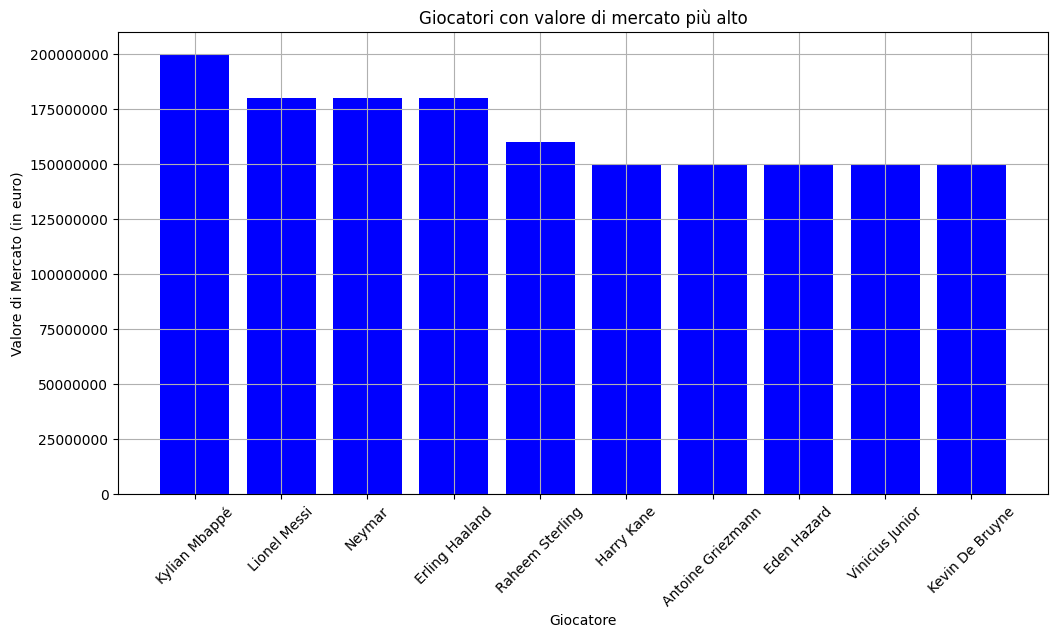

In [19]:
#adesso vado ad analizzare i 10 giocatori che hanno avuto valore di mercato più alto

player_df= pd.read_csv('players.csv')[['player_id','name']]
player_val = pd.merge(val_df, player_df, how='left', on='player_id')
player_val.rename(columns={'name': 'player_name'}, inplace=True)

max_market_value_by_player = player_val.groupby('player_name')['market_value_in_eur'].max().reset_index()

top_10_players = max_market_value_by_player.sort_values(by='market_value_in_eur', ascending=False).head(10)

plt.figure(figsize=(12, 6))
plt.bar(top_10_players['player_name'], top_10_players['market_value_in_eur'], color='blue')
plt.xlabel('Giocatore')
plt.ylabel('Valore di Mercato (in euro)')
plt.title('Giocatori con valore di mercato più alto')
plt.xticks(rotation=45)
plt.ticklabel_format(style='plain', axis='y')
plt.grid(True)
plt.show()

#così ho ottenuto i 10 calciatori che sono stati venduti al costo più alto.

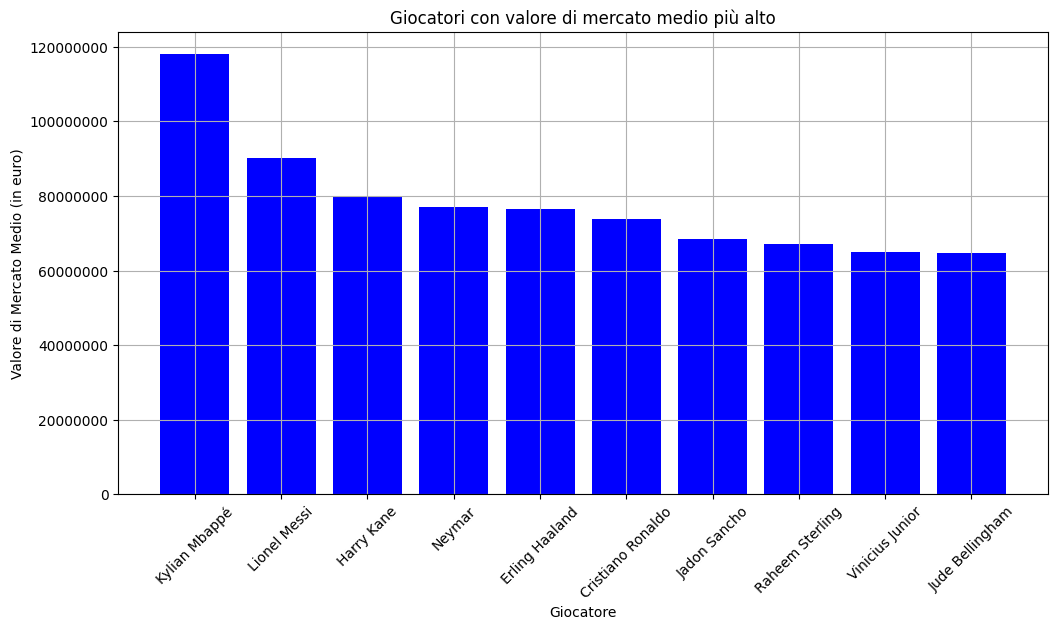

In [20]:
#adesso invece vado ad analizzare i 10 calciatori con il valore di vendita medio più alto

mean_market_value_by_player = player_val.groupby('player_name')['market_value_in_eur'].mean().reset_index()

top_10_players = mean_market_value_by_player.sort_values(by='market_value_in_eur', ascending=False).head(10)

plt.figure(figsize=(12, 6))
plt.bar(top_10_players['player_name'], top_10_players['market_value_in_eur'], color='blue')
plt.xlabel('Giocatore')
plt.ylabel('Valore di Mercato Medio (in euro)')
plt.title('Giocatori con valore di mercato medio più alto')
plt.xticks(rotation=45)
plt.ticklabel_format(style='plain', axis='y')
plt.grid(True)
plt.show()

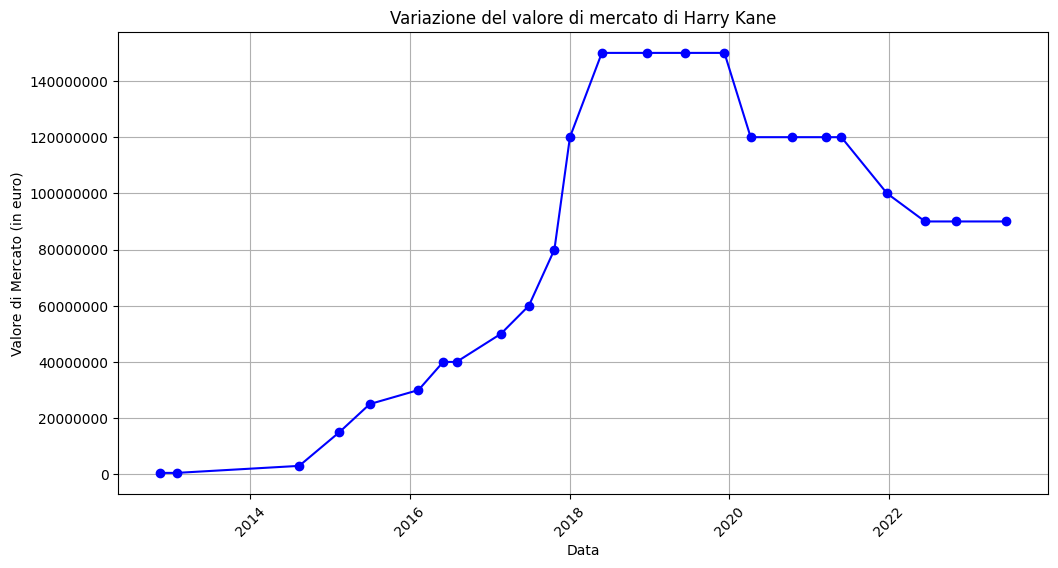

In [23]:
#rappresento la variazione del prezzo di vendita di un giocatore x.
#come giocatore esempio prenderò in analisi il giocatore 'Harry Kane'. Questo perchè dai grafici ottenuti prima
#possiamo denutare che: nonostanto attualmente sia il 6sto giocatore col prezzo di vendita più alto, è il 3zo giocatore col prezzo
#di vendita medio più alto, quindi possiamo presupporre che il suo valore sia variato nel tempo.

harry_kane_data = player_val[player_val['player_name'] == 'Harry Kane']

harry_kane_data = harry_kane_data.sort_values(by='date')

plt.figure(figsize=(12, 6))
plt.plot(harry_kane_data['date'], harry_kane_data['market_value_in_eur'], marker='o', linestyle='-', color='blue')
plt.xlabel('Data')
plt.ylabel('Valore di Mercato (in euro)')
plt.title('Variazione del valore di mercato di Harry Kane')
plt.xticks(rotation=45)
plt.ticklabel_format(style='plain', axis='y')
plt.grid(True)
plt.show()

In [49]:
#adesso andremo ad analizzare le perstazioni di 'Harry Kane' nell'arco della sua carriera. per farlo ci baseremo sul numero
#di goal e assist fatti.

collection_appearances = db['appearances']

documents = collection_appearances.find()

appearances_df = pd.DataFrame(list(documents)).drop('_id', axis=1)
appearances_df_filtred = appearances_df[['player_id', 'date', 'goals', 'assists']]
#prima mi prendo i dati di apperances dal database, dopo di che li filtro prendendo solo le colonne di mio interesse

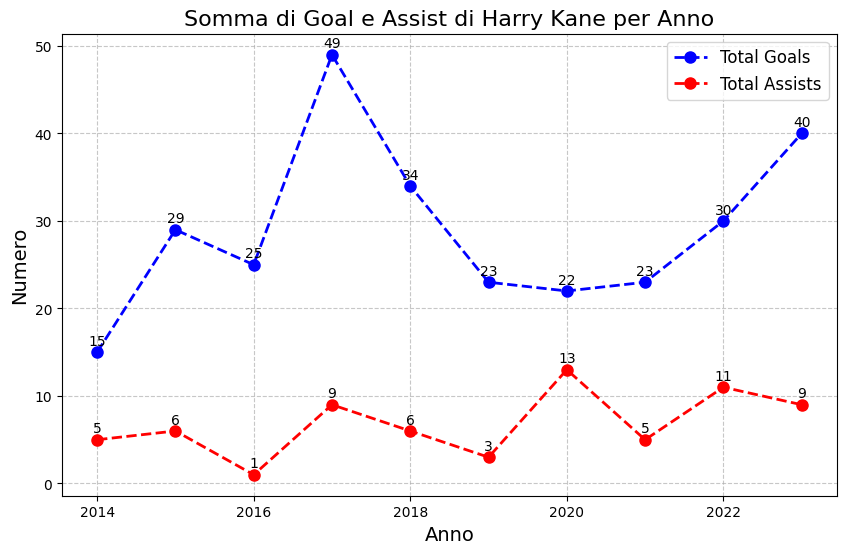

In [52]:
#ora vado a fare un merge per ottenere tutte le statistiche dei giocatori
players_stats = pd.merge(appearances_df_filtred, player_df, how='left', on='player_id')

#poi vado a filtrarle per le sole statistiche di 'Harry Kane', vado ad escludere le partite incui ha fatto 0 goal e 0 assist
#perché non andranno a variare il risultato del grafo perché saranno indicati i goal e gli assist annuali di Kane
Kane_stats = players_stats[players_stats['name'] == 'Harry Kane']
Kane_stats = Kane_stats[~((Kane_stats['goals'] == 0)&(Kane_stats['assists'] == 0))]

Kane_stats['date'] = pd.to_datetime(Kane_stats['date'], format='%d/%m/%Y')
Kane_stats['year'] = Kane_stats['date'].dt.year

annual_Kane_stats = Kane_stats.groupby('year')[['goals', 'assists']].sum().reset_index()

plt.figure(figsize=(10, 6))
plt.plot(annual_Kane_stats['year'], annual_Kane_stats['goals'], marker='o', color='b', label='Total Goals', linestyle='--', linewidth=2, markersize=8)
plt.plot(annual_Kane_stats['year'], annual_Kane_stats['assists'], marker='o', color='r', label='Total Assists', linestyle='--', linewidth=2, markersize=8)
plt.title('Somma di Goal e Assist di Harry Kane per Anno', fontsize=16)
plt.xlabel('Anno', fontsize=14)
plt.ylabel('Numero', fontsize=14)
plt.legend(fontsize=12)

for i in range(len(annual_Kane_stats)):
    plt.annotate(annual_Kane_stats['goals'][i], (annual_Kane_stats['year'][i], annual_Kane_stats['goals'][i]), textcoords="offset points", xytext=(0,5), ha='center', fontsize=10, color='black')
    plt.annotate(annual_Kane_stats['assists'][i], (annual_Kane_stats['year'][i], annual_Kane_stats['assists'][i]), textcoords="offset points", xytext=(0,5), ha='center', fontsize=10, color='black')

plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

#così facendo vado ad ottenere quanti goal e assist ha fatto ogni anno. Si può notare che intorno al 2017 'Harry Kane', segno il suo
#maggior numero di goal durante la sua carriera. Dal grafico precedente possiamo notare che sempre nello stesso anno il valore di mercato di Kane
#inizia a salire vertiginosamente da questo possiamo dedurre che, con l'aumentere dei goal durante l'anno il suo valore come giocatore all'interno
#del mercato sia salito.